# NPE on GALFORM with runs spread evenly over the prior: does the calibration dataset change the posterior?

Neural posterior estimation for **vhotdisk, alphahot and alpha_cool**, trained on the z = 0 luminosity functions of
dc-hick2's 667 L800 (P-Millennium) runs, then applied to five observed LFs:

| Dataset | Band | Age |
|---|---|---|
| Kochanek et al. 2001 | K | old |
| Cole et al. 2001 | K | old |
| Driver et al. 2012 (GAMA) | K | new |
| Norberg et al. 2002 | b_J | old |
| Driver et al. 2012 (GAMA) | r | new |

**Why these runs.** `npe_klf_calibration_data.ipynb` used history-matched runs already selected to fit the K LF, so the
LF had almost nothing left to say. These runs fill the prior evenly (a Latin hypercube), so no proposal correction is
needed: vhotdisk 150-750 km/s, alphahot 1-6, alpha_cool 0.1-2.

**Caveats.**
* The base model is **gp14, not lc16** (one IMF), so these posteriors can't be compared directly with Lacey et al.'s
  values. All other parameters are fixed at the gp14 values.
* Each run uses 64 of the 1024 L800 subvolumes.

**Method.** Like in the earlier notebook: x = ln φ at each dataset's magnitudes; noise σ² = σ_data² + σ_disc² with σ_disc = 0.2 in ln φ, redrawn each epoch; train/validation/test split by run; an ensemble of 5 flows; shuffled-LF controls.
New here is Section 6: a posterior predictive check of whether the model can reproduce each dataset at all.

Sources: `.../galform_clustering_calibration/data/lf_runs.h5` and `dataset_l800.h5`; observations from `galform/Obs_Data2`.

In [1]:
import h5py
import numpy as np
import torch
import matplotlib.pyplot as plt
from sbi.inference.posteriors import DirectPosterior
from sbi.neural_nets import posterior_nn
from sbi.utils import BoxUniform
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import cross_val_predict

torch.set_num_threads(8)
SEED = 20261102
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

CAL = "/cosma/apps/durham/dc-hick2/galform_clustering_calibration/data"
OBS = "/cosma/apps/durham/dc-lock1/galform/Obs_Data2"
IVOL_VOLUME = 542.16**3 / 1024  # (Mpc/h)^3
VEGA_MINUS_AB = {"K": -1.870, "bJ": 0.089}  # GALFORM's A0-AB offsets
SIGMA_DISC = 0.2                # model discrepancy, in ln(phi)
N_ENSEMBLE, N_POST = 5, 1000
N_TEST, N_VAL = 67, 67
# AB magnitudes fitted in each band: bright end where the data exist, faint end before resolution matters
MAG_RANGE = {"k": (-23.75, -18.5), "bj": (-22.8, -16.0), "r": (-23.4, -17.75)}

/cosma/apps/durham/dc-lock1/.venvs/galform_venv/lib64/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


## 1. Load the runs
φ = counts summed over the 64 subvolumes / (64 × subvolume volume × bin width), with empty bins floored at 0.5 galaxies.

In [2]:
f = h5py.File(f"{CAL}/lf_runs.h5", "r")
d = h5py.File(f"{CAL}/dataset_l800.h5", "r")
assert np.array_equal(f["l800/sids"][:], d["sample_ids"][:])
PARAMS = [n.decode() if isinstance(n, bytes) else n for n in d["param_names"][:]]
thetas = d["thetas"][:]
BOUNDS = np.array([[150.0, 750.0], [1.0, 6.0], [0.1, 2.0]])  # prior_bounds in designs/lhs_design_l800.json
theta = (thetas - BOUNDS[:, 0]) / (BOUNDS[:, 1] - BOUNDS[:, 0])
edges = f["lf_edges"][:]
mag_model = 0.5 * (edges[1:] + edges[:-1])

lnphi_model = {}
for band in MAG_RANGE:
    counts = f[f"l800/{band}/counts"][:].sum(axis=1)
    lnphi_model[band] = np.log(np.maximum(counts, 0.5) / (64 * IVOL_VOLUME * np.diff(edges)))
print(f"{len(theta)} runs; {PARAMS}; ranges {theta.min(0).round(3)} to {theta.max(0).round(3)}")
for band, (lo, hi) in MAG_RANGE.items():
    use = (mag_model > lo) & (mag_model < hi)
    drops = (np.diff(lnphi_model[band][:, use], axis=1) < -0.1).any(axis=1).mean()
    print(f"{band}: fraction of runs whose LF falls by > 0.1 in ln phi going fainter inside the fitted range: {drops:.2f}")

667 runs; ['vhotdisk', 'alphahot', 'alpha_cool']; ranges [0.001 0.    0.001] to [1.    1.    0.999]
k: fraction of runs whose LF falls by > 0.1 in ln phi going fainter inside the fitted range: 0.17
bj: fraction of runs whose LF falls by > 0.1 in ln phi going fainter inside the fitted range: 0.11
r: fraction of runs whose LF falls by > 0.1 in ln phi going fainter inside the fitted range: 0.15


## 2. Observed LFs, in the model's conventions
AB, M − 5 log h, ln φ with φ per mag, σ in ln φ.

In [3]:
def load_kochanek():
    m, l, e = np.loadtxt(f"{OBS}/lfK_Kochanek2001.data", unpack=True)  # Vega, log10 phi
    return m - VEGA_MINUS_AB["K"], l * np.log(10), e * np.log(10)

def load_cole():
    m, p, e = np.loadtxt(f"{OBS}/lfJK_Cole2001.data", usecols=(0, 3, 4), unpack=True)  # Vega
    ok = p > 0
    return m[ok] - VEGA_MINUS_AB["K"], np.log(p[ok]), e[ok] / p[ok]

def load_norberg():
    p, m, e = np.loadtxt(f"{OBS}/lfBJ_norberg02.data", usecols=(0, 1, 2), unpack=True)  # Vega
    ok = p > 0
    return m[ok] - VEGA_MINUS_AB["bJ"], np.log(p[ok]), e[ok] / p[ok]

def load_driver(band):
    m, p, e = np.loadtxt(f"{OBS}/lf{band}_z0_driver12.data", usecols=(0, 1, 2), unpack=True)  # AB, per 0.5 mag
    ok = p > 0
    return m[ok], np.log(p[ok] / 0.5), e[ok] / p[ok]

SOURCES = {
    "Kochanek+01 K": ("k", load_kochanek, "C0"),
    "Cole+01 K": ("k", load_cole, "C1"),
    "Driver+12 K": ("k", lambda: load_driver("k"), "C3"),
    "Norberg+02 bJ": ("bj", load_norberg, "C2"),
    "Driver+12 r": ("r", lambda: load_driver("r"), "C4"),
}
DATASETS = {}
for name, (band, loader, colour) in SOURCES.items():
    m, l, s = loader()
    use = (m > MAG_RANGE[band][0]) & (m < MAG_RANGE[band][1])
    DATASETS[name] = dict(band=band, colour=colour, mag=m[use], lnphi=l[use], sigma=s[use])
    print(f"{name:15s} {use.sum():2d} bins, {m[use].min():.2f} to {m[use].max():.2f}, median sigma_ln {np.median(s[use]):.2f}")

def sim_at(d_):
    return np.array([np.interp(d_["mag"], mag_model, l) for l in lnphi_model[d_["band"]]])

X = {name: sim_at(d_) for name, d_ in DATASETS.items()}

Kochanek+01 K   21 bins, -23.63 to -18.63, median sigma_ln 0.46
Cole+01 K       21 bins, -23.63 to -18.63, median sigma_ln 0.09
Driver+12 K     10 bins, -23.25 to -18.75, median sigma_ln 0.04
Norberg+02 bJ   25 bins, -22.71 to -16.11, median sigma_ln 0.02
Driver+12 r     11 bins, -23.25 to -18.25, median sigma_ln 0.04


## 3. How much do the parameters affect each dataset's LF?
Cross-validated ridge regression of each parameter on the LF at that dataset's bins, with that dataset's noise added.
This is a lower limit on the information, since it only sees linear relations.

In [4]:
def add_noise(x, d_):
    return x + rng.normal(size=x.shape) * np.sqrt(d_["sigma"]**2 + SIGMA_DISC**2)

print(f"{'dataset':16s}" + "".join(f"{p:>12s}" for p in PARAMS))
for name, d_ in DATASETS.items():
    x = add_noise(X[name], d_)
    x = (x - x.mean(0)) / x.std(0)
    row = []
    for j in range(3):
        p = cross_val_predict(RidgeCV(alphas=np.logspace(-3, 3, 13)), x, theta[:, j], cv=10)
        row.append(1 - np.mean((p - theta[:, j])**2) / theta[:, j].var())
    print(f"{name:16s}" + "".join(f"{v:12.2f}" for v in row))

dataset             vhotdisk    alphahot  alpha_cool
Kochanek+01 K           0.37        0.66        0.50
Cole+01 K               0.41        0.72        0.53
Driver+12 K             0.42        0.72        0.52
Norberg+02 bJ           0.38        0.82        0.45
Driver+12 r             0.37        0.70        0.47


## 4. Train the networks
Split by run, so early stopping sees runs it has never trained on. Noise is redrawn every epoch. The control network gets
LFs shuffled between runs: it has no information, so its shrinkage is the baseline to beat.

In [5]:
prior = BoxUniform(low=torch.zeros(3), high=torch.ones(3))
perm = rng.permutation(len(theta))
test_idx, val_idx, train_idx = perm[:N_TEST], perm[N_TEST:N_TEST + N_VAL], perm[N_TEST + N_VAL:]
T = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)

def train_one(x_runs, d_, seed, patience=50):
    torch.manual_seed(seed)
    tr, va = train_idx, val_idx
    x0 = add_noise(np.repeat(x_runs[tr], 20, 0), d_)
    net = posterior_nn(model="nsf", hidden_features=32, num_transforms=3)(T(np.repeat(theta[tr], 20, 0)), T(x0))
    opt = torch.optim.Adam(net.parameters(), lr=5e-4, weight_decay=1e-4)
    x_val, t_val = T(add_noise(np.repeat(x_runs[va], 50, 0), d_)), T(np.repeat(theta[va], 50, 0))
    best, bad, state = np.inf, 0, None
    while bad < patience:
        x, t = T(add_noise(np.repeat(x_runs[tr], 4, 0), d_)), T(np.repeat(theta[tr], 4, 0))
        net.train()
        for b in torch.randperm(len(t)).split(128):
            opt.zero_grad()
            net.loss(t[b], x[b]).mean().backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = net.loss(t_val, x_val).mean().item()
        if v < best - 1e-3:
            best, bad, state = v, 0, {k: p.clone() for k, p in net.state_dict().items()}
        else:
            bad += 1
    net.load_state_dict(state)
    return DirectPosterior(posterior_estimator=net, prior=prior)

def sample_ensemble(members, x_o, n):
    return np.concatenate([m.sample((n // len(members),), x=T(x_o), show_progress_bars=False).numpy() for m in members])

ensembles, controls = {}, {}
for name, d_ in DATASETS.items():
    ensembles[name] = [train_one(X[name], d_, SEED + k) for k in range(N_ENSEMBLE)]
    shuffled = X[name][rng.permutation(len(theta))]
    controls[name] = [train_one(shuffled, d_, SEED + 100 + k) for k in range(N_ENSEMBLE)]
    print(f"trained {name}", flush=True)

trained Kochanek+01 K
trained Cole+01 K
trained Driver+12 K
trained Norberg+02 bJ
trained Driver+12 r


## 5. Check the networks on held-out runs
**Coverage**: fraction of the 67 held-out runs whose true value lies in the central 68% (95%) interval; the uncertainty
is about ±0.06 (±0.03). **Information** is the shrinkage (1 − posterior variance / prior variance) above the shuffled control.

In [6]:
train_var = theta[train_idx].var(axis=0)

def held_out_check(members, name):
    d_ = DATASETS[name]
    x_test = add_noise(X[name][test_idx], d_)
    ranks, shrink, width = [], [], []
    for x_o, true in zip(x_test, theta[test_idx]):
        s = sample_ensemble(members, x_o, N_POST)
        ranks.append((s < true).mean(axis=0))
        shrink.append(1 - s.var(axis=0) / train_var)
    ranks = np.array(ranks)
    return ((ranks > 0.16) & (ranks < 0.84)).mean(0), ((ranks > 0.025) & (ranks < 0.975)).mean(0), np.mean(shrink, 0)

checks = {n: (held_out_check(ensembles[n], n), held_out_check(controls[n], n)) for n in DATASETS}
for n, ((c68, c95, sh), (_, _, sh0)) in checks.items():
    print(f"\n{n}\n  {'parameter':11s} {'cov68':>6s} {'cov95':>6s} {'shrink':>7s} {'control':>8s} {'information':>12s}")
    for j, p in enumerate(PARAMS):
        print(f"  {p:11s} {c68[j]:6.2f} {c95[j]:6.2f} {sh[j]:7.2f} {sh0[j]:8.2f} {sh[j] - sh0[j]:12.2f}")

/cosma/apps/durham/dc-lock1/.venvs/galform_venv/lib64/python3.9/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at /pytorch/aten/src/ATen/native/BatchLinearAlgebra.cpp:2264.)
  outputs, _ = torch.triangular_solve(



Kochanek+01 K
  parameter    cov68  cov95  shrink  control  information
  vhotdisk      0.67   0.91    0.62     0.05         0.56
  alphahot      0.63   0.87    0.84     0.06         0.77
  alpha_cool    0.84   0.97    0.59     0.05         0.54

Cole+01 K
  parameter    cov68  cov95  shrink  control  information
  vhotdisk      0.69   0.93    0.77     0.07         0.71
  alphahot      0.63   0.94    0.90     0.06         0.84
  alpha_cool    0.76   0.99    0.62     0.04         0.58

Driver+12 K
  parameter    cov68  cov95  shrink  control  information
  vhotdisk      0.72   0.93    0.73     0.06         0.67
  alphahot      0.67   0.93    0.88     0.07         0.81
  alpha_cool    0.75   0.96    0.61     0.07         0.54

Norberg+02 bJ
  parameter    cov68  cov95  shrink  control  information
  vhotdisk      0.75   0.94    0.68     0.05         0.63
  alphahot      0.70   0.93    0.91     0.06         0.85
  alpha_cool    0.81   0.94    0.59     0.06         0.52

Driver+12 r
  par

## 6. Posteriors from the real data
Dotted: the shuffled control given the same data. The prior is flat over each axis.

dataset                           vhotdisk                  alphahot                alpha_cool
Kochanek+01 K          449 [   291,   622]      2.91 [  2.32,   4.2]     0.612 [ 0.549, 0.666]
Cole+01 K              320 [   270,   448]      4.02 [  3.07,  4.83]     0.596 [ 0.549, 0.618]
Driver+12 K            319 [   257,   457]      3.89 [  2.92,  4.82]     0.614 [ 0.551, 0.649]
Norberg+02 bJ          246 [   219,   312]      4.69 [  3.87,  5.29]     0.799 [ 0.699, 0.857]
Driver+12 r            341 [   247,   578]      3.77 [  2.67,  5.14]     0.548 [  0.46, 0.599]

GAMA K against the old K data: shift of the median, in units of the combined posterior width
  vs Kochanek+01 K    vhotdisk -0.7  alphahot +0.7  alpha_cool +0.0
  vs Cole+01 K        vhotdisk -0.0  alphahot -0.1  alpha_cool +0.3


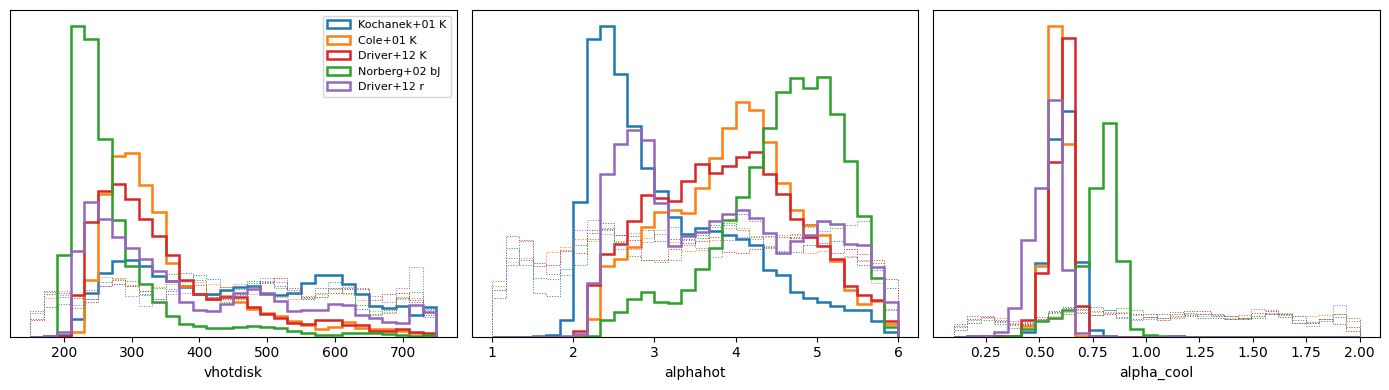

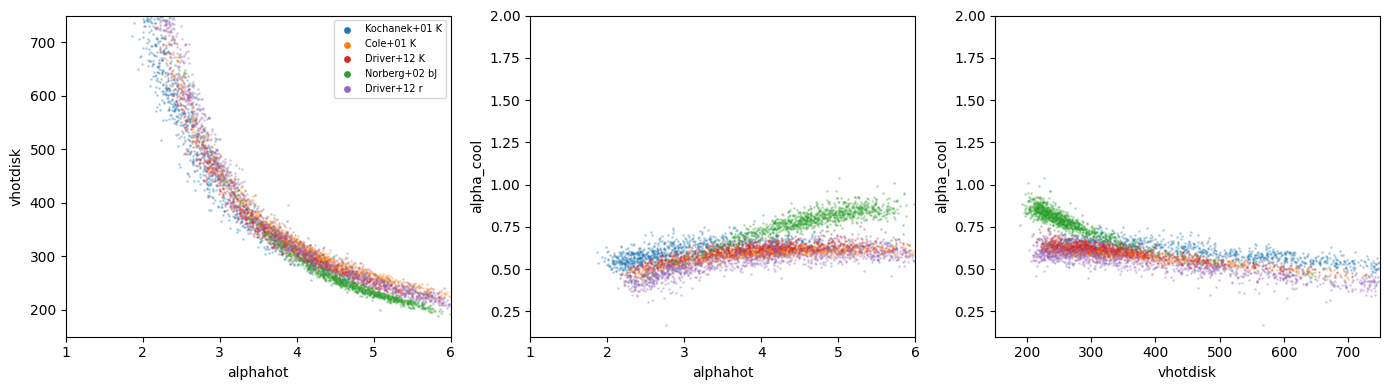

In [7]:
to_phys = lambda u: BOUNDS[:, 0] + u * (BOUNDS[:, 1] - BOUNDS[:, 0])
samples = {n: to_phys(sample_ensemble(ensembles[n], d_["lnphi"], 20000)) for n, d_ in DATASETS.items()}
ctrl = {n: to_phys(sample_ensemble(controls[n], d_["lnphi"], 20000)) for n, d_ in DATASETS.items()}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for j, ax in enumerate(axes):
    bins = np.linspace(*BOUNDS[j], 31)
    for n, d_ in DATASETS.items():
        ax.hist(samples[n][:, j], bins=bins, density=True, histtype="step", lw=1.8, color=d_["colour"], label=n)
        ax.hist(ctrl[n][:, j], bins=bins, density=True, histtype="step", lw=0.7, ls=":", color=d_["colour"])
    ax.set_xlabel(PARAMS[j])
    ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (a, b) in zip(axes, [(1, 0), (1, 2), (0, 2)]):
    for n, d_ in DATASETS.items():
        ax.scatter(samples[n][::20, a], samples[n][::20, b], s=1, alpha=0.25, color=d_["colour"])
        ax.scatter([], [], s=15, color=d_["colour"], label=n)
    ax.set_xlabel(PARAMS[a]); ax.set_ylabel(PARAMS[b])
    ax.set_xlim(*BOUNDS[a]); ax.set_ylim(*BOUNDS[b])
axes[0].legend(fontsize=7)
fig.tight_layout()

print(f"{'dataset':16s}" + "".join(f"{p:>26s}" for p in PARAMS))
for n in DATASETS:
    q = np.percentile(samples[n], [16, 50, 84], axis=0)
    print(f"{n:16s}" + "".join(f"{q[1, j]:10.3g} [{q[0, j]:6.3g},{q[2, j]:6.3g}]" for j in range(3)))

print("\nGAMA K against the old K data: shift of the median, in units of the combined posterior width")
g = samples["Driver+12 K"]
for o in ("Kochanek+01 K", "Cole+01 K"):
    a = samples[o]
    wid = lambda s: (np.percentile(s, 84, axis=0) - np.percentile(s, 16, axis=0)) / 2
    shift = (np.median(g, 0) - np.median(a, 0)) / np.hypot(wid(g), wid(a))
    print(f"  vs {o:15s}" + "".join(f"  {p} {v:+.1f}" for p, v in zip(PARAMS, shift)))

## 7. Can the model actually reproduce the data?
A posterior is only meaningful if its parameters reproduce the observations. A flow given data outside the range of its
training set still returns an answer, so this has to be checked separately. A small Gaussian process emulator (trained on
the same training runs and tested on the held-out runs) predicts the LF for posterior samples, and the χ² is compared with
what held-out runs get when treated as data. If the real data's χ² is far above the held-out runs' range, the model can't
fit the data, and the posterior for that dataset is not trustworthy.

Kochanek+01 K    emulator rms error on held-out runs: 0.221 in ln phi
Cole+01 K        emulator rms error on held-out runs: 0.221 in ln phi
Driver+12 K      emulator rms error on held-out runs: 0.169 in ln phi
Norberg+02 bJ    emulator rms error on held-out runs: 0.165 in ln phi
Driver+12 r      emulator rms error on held-out runs: 0.166 in ln phi

dataset           best run  posterior predictive    held-out runs 50% [2.5, 97.5]   (chi2/bin)
Kochanek+01 K         0.27                  0.55               1.10 [0.67, 1.94]
Cole+01 K             1.35                  1.30               1.54 [0.91, 4.24]
Driver+12 K           0.62                  1.46               1.50 [0.67, 2.35]
Norberg+02 bJ         0.65                  0.70               1.32 [0.67, 2.37]
Driver+12 r           0.50                  1.37               1.41 [0.71, 2.78]


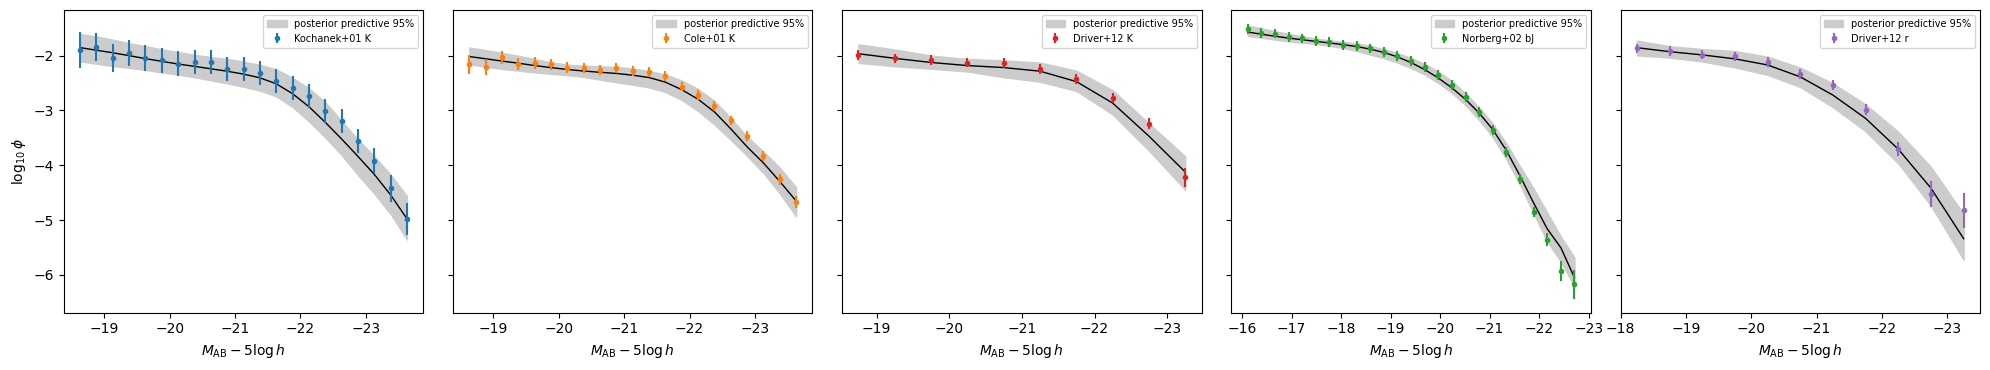

In [8]:
kernel = ConstantKernel(1.0) * RBF([0.5, 0.5, 0.5], (1e-2, 1e2)) + WhiteKernel(1e-3, (1e-6, 1.0))
emus = {}
for n, d_ in DATASETS.items():
    gp = GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=2, random_state=0)
    emus[n] = gp.fit(theta[train_idx], X[n][train_idx])
    err = gp.predict(theta[test_idx]) - X[n][test_idx]
    print(f"{n:16s} emulator rms error on held-out runs: {np.sqrt((err**2).mean()):.3f} in ln phi")

def chi2_bin(pred, d_, y):
    return ((pred - y)**2 / (d_["sigma"]**2 + SIGMA_DISC**2)).mean(axis=-1)

ppc = {}
print(f"\n{'dataset':16s} {'best run':>9s} {'posterior predictive':>21s} {'held-out runs 50% [2.5, 97.5]':>32s}   (chi2/bin)")
for n, d_ in DATASETS.items():
    best_run = chi2_bin(X[n], d_, d_["lnphi"]).min()
    u = (samples[n][::20] - BOUNDS[:, 0]) / (BOUNDS[:, 1] - BOUNDS[:, 0])
    pred = emus[n].predict(u)
    real = chi2_bin(pred, d_, d_["lnphi"])
    null = []
    for i in test_idx:
        y = add_noise(X[n][i][None], d_)[0]
        s = sample_ensemble(ensembles[n], y, 200)
        null.append(np.median(chi2_bin(emus[n].predict(s), d_, y)))
    ppc[n] = dict(pred=pred, real=np.median(real), null=np.percentile(null, [2.5, 50, 97.5]))
    print(f"{n:16s} {best_run:9.2f} {np.median(real):21.2f} {ppc[n]['null'][1]:18.2f} [{ppc[n]['null'][0]:.2f}, {ppc[n]['null'][2]:.2f}]")

fig, axes = plt.subplots(1, len(DATASETS), figsize=(4 * len(DATASETS), 3.8), sharey=True)
for ax, (n, d_) in zip(axes, DATASETS.items()):
    lo, mid, hi = np.percentile(ppc[n]["pred"], [2.5, 50, 97.5], axis=0) / np.log(10)
    ax.fill_between(d_["mag"], lo, hi, color="0.8", label="posterior predictive 95%")
    ax.plot(d_["mag"], mid, "k", lw=1)
    ax.errorbar(d_["mag"], d_["lnphi"] / np.log(10), yerr=np.hypot(d_["sigma"], SIGMA_DISC) / np.log(10), fmt="o", ms=3,
                color=d_["colour"], label=n)
    ax.invert_xaxis()
    ax.set_xlabel(r"$M_{\rm AB} - 5\log h$")
    ax.legend(fontsize=7)
axes[0].set_ylabel(r"$\log_{10}\phi$")
fig.tight_layout()

## 8. Direct check, with no network
χ² of every run against each dataset. If the old and GAMA data prefer different physics, their best-fitting runs should
sit in different places.

In [9]:
chi2 = {n: chi2_bin(X[n], d_, d_["lnphi"]) for n, d_ in DATASETS.items()}
best = {n: np.argsort(c)[:len(theta) // 10] for n, c in chi2.items()}
print(f"{'dataset':16s}" + "".join(f"{p:>12s}" for p in PARAMS) + f"{'chi2/bin':>10s}   (median of best 10%)")
for n in DATASETS:
    print(f"{n:16s}" + "".join(f"{v:12.3g}" for v in np.median(thetas[best[n]], axis=0)) + f"{np.median(chi2[n][best[n]]):10.2f}")
print(f"{'all runs':16s}" + "".join(f"{v:12.3g}" for v in np.median(thetas, axis=0)))
ks = ["Kochanek+01 K", "Cole+01 K", "Driver+12 K"]
print(f"\nbest 10% ({len(theta) // 10} runs) shared by all three K datasets: {len(set.intersection(*[set(best[n]) for n in ks]))}")
print(f"shared by Cole K and Driver K: {len(set(best['Cole+01 K']) & set(best['Driver+12 K']))}")
print(f"shared by Norberg bJ and Driver r: {len(set(best['Norberg+02 bJ']) & set(best['Driver+12 r']))}")

dataset             vhotdisk    alphahot  alpha_cool  chi2/bin   (median of best 10%)
Kochanek+01 K            417        2.92       0.654      3.39
Cole+01 K                415        3.06       0.614     18.85
Driver+12 K              415        3.12       0.493     15.76
Norberg+02 bJ            292        3.98       0.851     12.41
Driver+12 r              353        3.52       0.442     10.46
all runs                 448        3.49        1.06

best 10% (66 runs) shared by all three K datasets: 44
shared by Cole K and Driver K: 47
shared by Norberg bJ and Driver r: 22


## Conclusions (written after the run; numbers quoted from the outputs above)
* **The networks now work.** Held-out coverage is 0.63-0.84 (68%) and 0.87-0.99 (95%), and information above the shuffled control is 0.5-0.85, against about 0.1 for the history-matched runs. This coverage averages over the whole prior, not just the region near the data.
* **Old and new K data agree.** Cole and GAMA K differ by at most 0.3 sigma in every parameter. Kochanek differs by 0.7 sigma in vhotdisk and alphahot.
* **alpha_cool is the best constrained, near 0.6** (the gp14 value) in K. **Bands disagree on it:** b_J gives 0.80 [0.70, 0.86]. This is a band difference, not an old-vs-new difference, because no dataset exists in both.
* **vhotdisk and alphahot are degenerate**, and alphahot below about 2 is disfavoured by all five datasets.
* **Few runs fit well:** only 1-2 of 667 reach chi2/bin < 2 for any of Cole K, GAMA K, Norberg b_J or GAMA r, so the posterior near the data rests on few runs. The posterior predictive test passes, but the emulator's error (0.17-0.22 in ln phi) is about as large as sigma_disc, so that test is lenient.
* The result assumes sigma_disc = 0.2 and the gp14 base model; the other 16 parameters are fixed. `joint_band_check.py` tests two bands at once without a network.